In [22]:
import pandas as pd
import numpy as np

df_test = pd.read_csv('../data/test.csv')
df_train = pd.read_csv('../data/train.csv')

df_summary = pd.DataFrame({'dtype': df_train.dtypes, 'nulls': df_train.isna().sum(), 'nununique': df_train.nunique(), 'sample_1': df_train.iloc[0], 'sample_2': df_train.iloc[1], 'sample_3': df_train.iloc[2]})
df_summary



,dtype,nulls,nununique,sample_1,sample_2,sample_3
Id,int64,0,1460,1,2,3
MSSubClass,int64,0,15,60,20,60
MSZoning,str,0,5,RL,RL,RL
LotFrontage,float64,259,110,65.0,80.0,68.0
LotArea,int64,0,1073,8450,9600,11250
...,...,...,...,...,...,...
MoSold,int64,0,12,2,5,9
YrSold,int64,0,5,2008,2007,2008
SaleType,str,0,9,WD,WD,WD
SaleCondition,str,0,6,Normal,Normal,Normal


In [23]:
for df in [df_train, df_test]:
    df['Total_SF'] = df['GrLivArea'] + df['TotalBsmtSF']
    df['Total_Bathrooms'] = df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'] + df['FullBath'] + 0.5 * df['HalfBath']
    df['AgeAtSale'] = df['YrSold'] - df['YearBuilt']
    df['GarageSFPerCar'] = df['GarageArea'] / df['GarageCars']

In [24]:
num_cols = df_train.select_dtypes(include='number').columns.tolist()

cat_cols = df_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

ord_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageCond', 'GarageQual', 'PoolQC', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']

cat_cols = [col for col in cat_cols if col not in ord_cols]

ord_cols = [col for col in ord_cols if col in df_train.columns]

num_cols = [col for col in num_cols if col != 'SalePrice' and col != 'Id']

C:\Users\yazid\AppData\Local\Temp\ipykernel_10796\2204705351.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


In [25]:

quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
quality_order_none = ['None'] + quality_order
exposure_none_order = ['None', 'No', 'Mn', 'Av', 'Gd']
finish_none_order = ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ']
pool_none_order = ['None', 'Fa', 'Gd', 'Ex']

regular_ord_cols = ['ExterQual', 'ExterCond', 'HeatingQC', 'KitchenQual']
none_ord_cols = ['BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'BsmtQual', 'BsmtCond', 'GarageCond', 'GarageQual', 'PoolQC', 'FireplaceQu']
print(cat_cols)
none_cat_cols = ['Alley', 'MasVnrType', 'GarageType', 'GarageFinish', 'Fence', 'MiscFeature']
regular_cat_cols = [col for col in cat_cols if col not in none_cat_cols]


['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'Functional', 'GarageType', 'GarageFinish', 'PavedDrive', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [26]:

ordinal_categories = {
    'ExterQual': quality_order,
    'ExterCond': quality_order,
    'BsmtQual': quality_order_none,
    'BsmtCond': quality_order_none,
    'HeatingQC': quality_order,
    'KitchenQual': quality_order,
    'FireplaceQu': quality_order_none,
    'GarageCond': quality_order_none,
    'GarageQual': quality_order_none,
    'PoolQC': pool_none_order,
    'BsmtExposure': exposure_none_order,
    'BsmtFinType1': finish_none_order,
    'BsmtFinType2': finish_none_order
}

regular_categories = [ordinal_categories[col] for col in regular_ord_cols]
none_categories = [ordinal_categories[col] for col in none_ord_cols]



In [27]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

num_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='median'))])
regular_cat_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))])
none_cat_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='constant', fill_value='None')), ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))])
regular_ord_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder(categories=regular_categories, handle_unknown='use_encoded_value', unknown_value=-1))])
none_ord_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='constant', fill_value='None')), ('ordinal', OrdinalEncoder(categories=none_categories, handle_unknown='use_encoded_value', unknown_value=-1))])

param_distributions = {
    'model__n_estimators': [100, 300, 600, 1000],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__max_depth': [2,3,4,5,6],
    'model__min_child_weight': [1,3,5],
    'model__subsample': [0.8,0.9,1.0]
}
preprocessor = ColumnTransformer(transformers=[('num', num_pipeline, num_cols), ('regular_cat', regular_cat_pipeline, regular_cat_cols), ('none_cat', none_cat_pipeline, none_cat_cols), ('regular_ord', regular_ord_pipeline, regular_ord_cols), ('none_ord', none_ord_pipeline, none_ord_cols)])

model1 = XGBRegressor(learning_rate=0.01, n_estimators=100, random_state=42, max_depth=6)

full_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model1)])

X_train = df_train.drop(columns=['SalePrice', 'Id'])
X_test = df_test.drop(columns=['Id'])
y_train = np.log1p(df_train['SalePrice'])
test_id = df_test['Id']

In [28]:
from sklearn.dummy import DummyRegressor
from xgboost import cv
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

baseline = DummyRegressor(strategy='mean')

baseline_scores = cross_val_score(
    baseline, 
    X_train,
    y_train,
    cv=cv,
    scoring='neg_mean_squared_error'
)

baseline_rmsle = np.sqrt(-baseline_scores.mean())

In [29]:

msle = cross_val_score(full_pipeline, X_train, y_train, cv=cv, scoring='neg_mean_squared_error')
rmsle = np.sqrt(-msle.mean())

print(baseline_rmsle, rmsle)

0.3995729236866519 0.21463379552343842


In [30]:
search = RandomizedSearchCV(
    estimator=full_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring='neg_mean_squared_error',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True,
    refit=False,
    error_score='raise'
)

search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)

In [31]:
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__subsample,param_model__n_estimators,param_model__min_child_weight,param_model__max_depth,param_model__learning_rate,params,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,2.695619,0.123527,0.082644,0.016600,0.9,300,3,6,0.03,"{'model__subsample': 0.9, 'model__n_estimators...",...,-0.018310,0.005834,15,-9.368434e-04,-9.104751e-04,-8.431483e-04,-9.993953e-04,-9.416951e-04,-9.263114e-04,5.070647e-05
1,0.960465,0.103823,0.077693,0.012284,1.0,100,1,5,0.03,"{'model__subsample': 1.0, 'model__n_estimators...",...,-0.020935,0.004041,21,-6.328943e-03,-6.458169e-03,-6.221327e-03,-6.557214e-03,-6.681136e-03,-6.449358e-03,1.624374e-04
2,1.654240,0.445877,0.064920,0.006703,0.8,600,3,3,0.01,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.017993,0.004638,14,-8.759051e-03,-9.011355e-03,-8.133370e-03,-8.955967e-03,-9.065955e-03,-8.785140e-03,3.419642e-04
3,1.003487,0.125745,0.061292,0.004397,0.8,600,3,2,0.03,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.016724,0.004612,3,-7.569093e-03,-7.740904e-03,-7.104955e-03,-7.786480e-03,-7.709908e-03,-7.582268e-03,2.494639e-04
4,3.036857,0.243363,0.068398,0.007279,0.8,1000,3,4,0.05,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.016634,0.004790,1,-2.016049e-04,-2.169232e-04,-1.816896e-04,-2.362585e-04,-1.989233e-04,-2.070799e-04,1.838182e-05
5,0.776136,0.022832,0.052532,0.002093,1.0,300,5,3,0.01,"{'model__subsample': 1.0, 'model__n_estimators...",...,-0.022804,0.004000,26,-1.532046e-02,-1.606454e-02,-1.434369e-02,-1.544720e-02,-1.615971e-02,-1.546712e-02,6.512424e-04
6,0.779965,0.074429,0.063081,0.012348,0.8,300,5,3,0.01,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.022104,0.003658,24,-1.530751e-02,-1.584806e-02,-1.426361e-02,-1.534966e-02,-1.603316e-02,-1.536040e-02,6.158407e-04
7,1.145226,0.149104,0.062430,0.014390,0.9,100,1,6,0.01,"{'model__subsample': 0.9, 'model__n_estimators...",...,-0.045751,0.006674,29,-3.236117e-02,-3.380518e-02,-3.425497e-02,-3.293503e-02,-3.493074e-02,-3.365742e-02,9.167750e-04
8,1.692859,0.105915,0.071759,0.012106,0.9,300,1,5,0.03,"{'model__subsample': 0.9, 'model__n_estimators...",...,-0.017919,0.004967,13,-1.807881e-03,-1.780741e-03,-1.663110e-03,-1.864840e-03,-1.867238e-03,-1.796762e-03,7.462535e-05
9,0.953485,0.037196,0.074186,0.005289,0.8,600,5,2,0.05,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.017254,0.005055,9,-5.926132e-03,-6.119133e-03,-5.601688e-03,-6.327863e-03,-6.072854e-03,-6.009534e-03,2.411012e-04


In [32]:
results['train_rmsle'] = np.sqrt(-results['mean_train_score'])

results['validation_rmsle'] = np.sqrt(
    -results['mean_test_score']
)

results['overfit_gap'] = (
    results['validation_rmsle'] - results['train_rmsle']
)

max_gap = 0.05

accepted_results = results[results['overfit_gap'] <= max_gap]

best_index = accepted_results['validation_rmsle'].idxmin()

best_params = results.loc[best_index, 'params']

In [33]:
from sklearn.base import clone

final_pipeline = clone(full_pipeline)
final_pipeline.set_params(**best_params)
final_pipeline.fit(X_train, y_train)

selected_scores = -cross_val_score(
    final_pipeline, 
    X_train, 
    y_train,
    cv=cv,
    scoring='neg_mean_squared_error'
)

print("Selected RMSLE:", np.sqrt(selected_scores.mean()))

Selected RMSLE: 0.12921415272994402


In [34]:
model = final_pipeline.named_steps['model']
preprocessor = final_pipeline.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

quality_analysis = (
    df_train.assign(LogSalePrice=np.log1p(df_train['SalePrice'])).groupby('ExterQual').agg(house_count=('LogSalePrice', 'size'), median_log_price=('LogSalePrice', 'median'), mean_log_price=(
        'LogSalePrice', 'mean'
    )).sort_values('median_log_price')
)

quality_analysis

,house_count,median_log_price,mean_log_price
ExterQual,,,
Fa,14,11.317526,11.304554
TA,906,11.845468,11.837993
Gd,488,12.301387,12.311287
Ex,52,12.806550,12.764047


In [35]:
numeric_df = df_train.select_dtypes(include='number').copy()

numeric_df['LogSalePrice'] = np.log1p(numeric_df['SalePrice'])

correlations = (numeric_df.corr()['LogSalePrice'].drop('LogSalePrice').sort_values(key=abs, ascending=False))

print(correlations.head(15))

SalePrice          0.948374
OverallQual        0.817185
Total_SF           0.773277
GrLivArea          0.700927
GarageCars         0.680625
Total_Bathrooms    0.673011
GarageArea         0.650888
TotalBsmtSF        0.612134
1stFlrSF           0.596981
FullBath           0.594771
AgeAtSale         -0.587290
YearBuilt          0.586570
YearRemodAdd       0.565608
GarageYrBlt        0.541073
TotRmsAbvGrd       0.534422
Name: LogSalePrice, dtype: float64


In [36]:
car_size = pd.DataFrame(df_train['GarageArea'] / df_train['GarageCars'])
car_size

,0
0,274.000000
1,230.000000
2,304.000000
3,214.000000
4,278.666667
...,...
1455,230.000000
1456,250.000000
1457,252.000000
1458,240.000000


In [37]:
from sklearn.feature_selection import mutual_info_regression

numeric_cols = df_train.select_dtypes(include='number').columns.tolist()
numeric_cols.remove('SalePrice')
numeric_cols.remove('Id')
X_numeric = df_train[numeric_cols].copy()

X_numeric = X_numeric.fillna(X_numeric.median())

y_log = np.log1p(df_train['SalePrice'])
mi_scores = mutual_info_regression(X_numeric, y_log, random_state=42)

mi_results = (
    pd.Series(mi_scores, index=numeric_cols).sort_values(ascending=False)
)

print(mi_results.head(20))

Total_SF           0.669716
OverallQual        0.571149
GrLivArea          0.456818
GarageArea         0.364214
TotalBsmtSF        0.361761
YearBuilt          0.361034
GarageCars         0.358765
Total_Bathrooms    0.340320
AgeAtSale          0.333316
1stFlrSF           0.298676
MSSubClass         0.287179
GarageYrBlt        0.285374
FullBath           0.268780
YearRemodAdd       0.232656
LotFrontage        0.230772
TotRmsAbvGrd       0.225506
2ndFlrSF           0.204575
LotArea            0.170957
OpenPorchSF        0.163962
Fireplaces         0.158848
dtype: float64


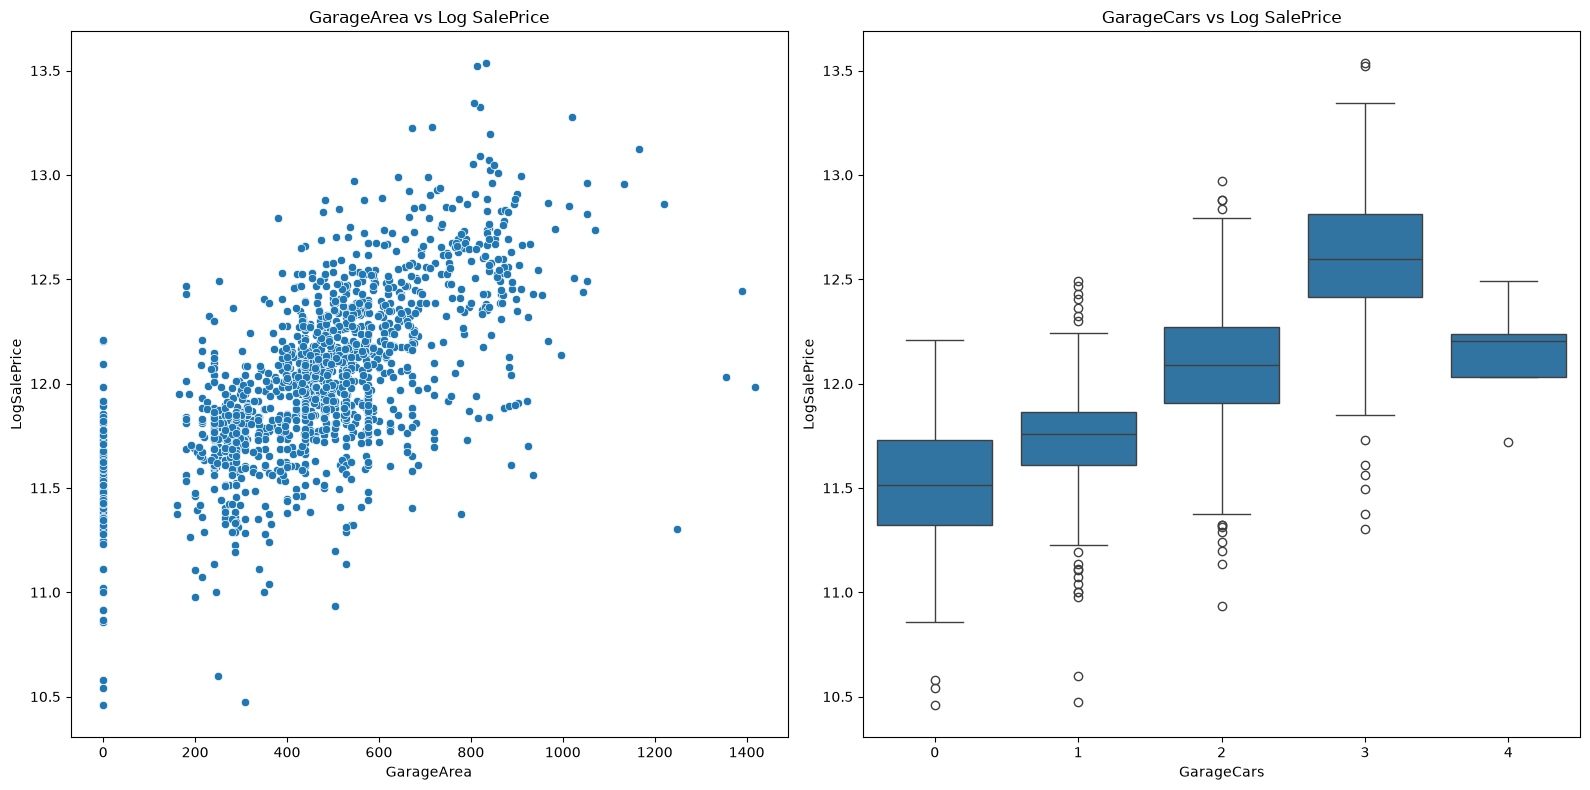

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = df_train.copy()
plot_data['LogSalePrice'] = np.log1p(plot_data['SalePrice'])

fig, axes = plt.subplots(1, 2, figsize=(16,8))

sns.scatterplot(data=plot_data,
                x='GarageArea', 
                y='LogSalePrice',
                ax=axes[0])

axes[0].set_title('GarageArea vs Log SalePrice')

sns.boxplot(data=plot_data, x='GarageCars', y='LogSalePrice', ax=axes[1])

axes[1].set_title('GarageCars vs Log SalePrice')
plt.tight_layout()
plt.savefig('garage_vis.png', bbox_inches='tight')
plt.show()

